# Taller Perceptrón y Adaline con SGD
- Luis Ángel Fornaris Rodríguez - 2019214048
- **Inteligencia artificial** Grupo 4
- **Semestre:** 2026-II
- **Docente:** 

### Objetivo general

Aplicar los algoritmos Perceptrón y Adaline usando scikit-learn para clasificar flores del conjunto Iris y analizar el efecto de la tasa
de aprendizaje y la selección de características. La evaluación de los resultados debe realizarse únicamente con accuracy_score

# Tabla de Contenidos

    1. Clasificación binaria con Perceptrón
        I. Cargue y prepare el conjunto de datos  
        II. Definición del Problema de Aprendizaje  
        III. Descripción del Dataset  
        IV. Relevancia Ética y Social  

    2. Influencia de la tasa de aprendizaje  
        I. Instalacion de librerias
        II. Carga y Estructura de los Datos  
        III. Distribución de Clases
        IV. Limpieza Preliminar (Nulos, Duplicados, Idioma)   
        V. Análisis de Longitud de los Textos   
        VI. Frecuencias y Palabras más Comunes  
        VII. Visualizaciones y Hallazgos  
        VIII. Conclusiones del EDA  
        IX. Filtrado de idioma

    3. Adaline con SGD
        I. Limpieza de Texto  
            A. Eliminación de menciones, URLs y caracteres especiales  
            B. Normalización y minúsculas  
            C. Sustitución por tokens `<MENTION>`, `<URL>`  
        II. Tokenización y Lematización  
        III. Vectorización (TF-IDF, Hashing, Embeddings)
        IV. Generación de Features Adicionales
        V. Separación del Conjunto de Datos (Train / Test / Val)
        Vi. Manejo de Desbalance de Clases   
        VII. Construcción del Pipeline  

    4. Comparación entre Perceptrón y Adaline
        I. Modelos Base  
            A. Baseline (Clase Mayoritaria)  
            B. Naive Bayes  
            C. Regresión Logística  
        II. Modelos Intermedios  
            A. Linear SVC  
            B. Random Forest  
            C. MLP (Red Neuronal Simple)  
        III. Modelos Avanzados  
            A. Fine-tuning con Transformers (DistilBERT / BERT)
            B. DNN - Deep learning network  
        IV. Optimización de Hiperparámetros (GridSearchCV / RandomizedSearchCV)  
        V. Validación Cruzada  

    5. Clasificación de las tres especies de Iris
        I. Métricas de Evaluación (Accuracy, F1, Recall, Precision)  
        II. Resultados en Validación Cruzada  
        III. Resultados en el Conjunto de Prueba  
        IV. Matriz de Confusión  
        V. Curvas ROC y Precision-Recall  
        VI. Comparativa Global de Modelos  

    6. Análisis de Errores e Interpretabilidad  
        I. Análisis de Falsos Positivos y Falsos Negativos  
        II. Tokens más Influyentes (Coeficientes / SHAP / LIME)  
        III. Impacto del Desbalance y Sesgo  
        IV. Discusión de Resultados y Aprendizajes  

    7. Conclusiones
        I. Conclusiones Principales  
        II. Limitaciones del Estudio  
        III. Propuestas de Mejora  
        IV. Reflexión Ética y Responsabilidad del Modelo  
        V. Reproducibilidad (Seeds, Versiones, Entorno)
        VI. Referencias bibliograficas



# Librerias necesarias

In [ ]:
# Librerias necesarias
from sklearn import datasets;
from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from mlxtend.plotting import plot_decision_regions
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd

# 1. Clasificación binaria con Perceptrón

## I. Cargue y prepare el conjunto de datos
Se carga el dataset Iris y se filtra para quedarnos únicamente con **Iris setosa** (clase 0)
e **Iris versicolor** (clase 1), descartando *Iris virginica* (clase 2).
Además se seleccionan **solo las variables longitud y anchura del pétalo**
(columnas 2 y 3 de `iris.data`).

In [6]:
# Cargando los datos de iris
iris = datasets.load_iris();
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
print(df.head())

# mascara para filtrar 
mask = iris.target != 2

X = iris.data[mask][:,[2,3]] # Logitud y ancho del petalo
y = iris.target[mask] # etiquetas de las clases


print("Forma de X:", X.shape)
print("Forma de y:", y.shape)
print("Clases presentes:", np.unique(y))
print("Nombres de las variables usadas:",
      [iris.feature_names[i] for i in [2, 3]])

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
Forma de X: (100, 2)
Forma de y: (100,)
Clases presentes: [0 1]
Nombres de las variables usadas: ['petal length (cm)', 'petal width (cm)']


## II. Gráfica de dispersión de las dos clases

Se grafican las dos clases en el plano (longitud vs anchura del pétalo) con
colores y marcadores distintos para poder observar visualmente su separabilidad.

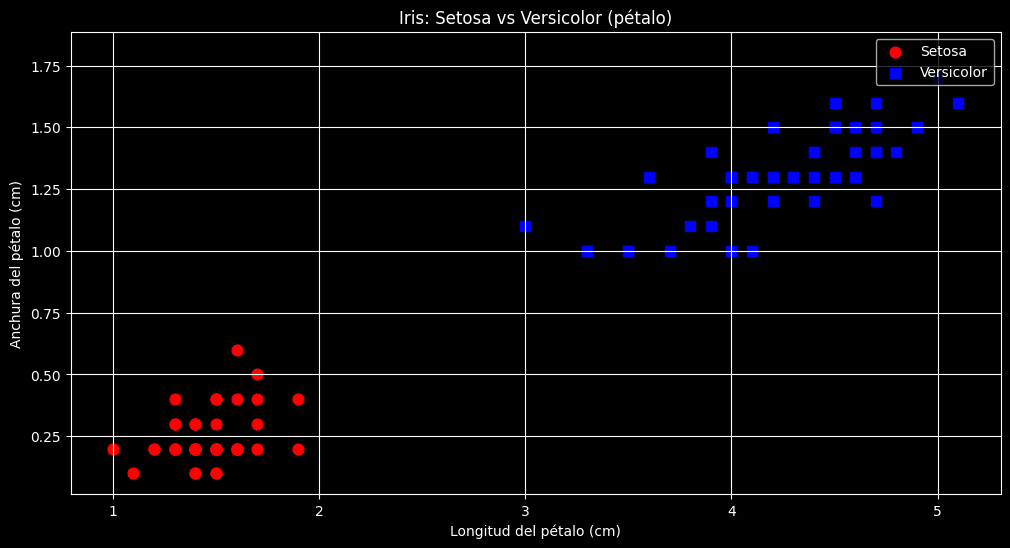

In [19]:

# Grafica de los datos
plt.style.use("dark_background")
plt.figure(figsize=(12, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1],
            color='red', marker='o', label='Setosa', s=60)
plt.scatter(X[y == 1, 0], X[y == 1, 1],
            color='blue', marker='s', label='Versicolor', s=60)
plt.xlabel('Longitud del pétalo (cm)')
plt.ylabel('Anchura del pétalo (cm)')
plt.title('Iris: Setosa vs Versicolor (pétalo)')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

Como se observa en la grafica se forman 2 nubes de puntos completamente separadas, ninguna esta encima de la otra.
Esto nos indica que son linealmente separables.

## III. División entrenamiento y prueba 

Se usa `train_test_split` con `test_size=0.2` y `stratify=y` para mantener
la proporción de clases en ambos conjuntos.

Después se aplica **StandardScaler** ajustándolo **únicamente con `X_train`**
(evitando fuga de información desde el conjunto de prueba).

In [ ]:
# Dvidir datos - Train y test
X_train, X_test, y_train, y_test = train_test_split(X,y,
                                                   test_size=0.3,
                                                   train_size=0.7,
                                                   random_state=42,
                                                   stratify=y,
                                                   shuffle=True)

# Estandarización - toma los valores y se ajusta en un rango entre 0 y 1
sc = StandardScaler()
X_train_std = sc.fit_transform(X_train)
X_test_std = sc.fit_transform(X_test)

-- Epoch 1
Norm: 0.19, NNZs: 2, Bias: 0.000000, T: 70, Avg. loss: 0.000427
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 0.19, NNZs: 2, Bias: 0.000000, T: 140, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 0.19, NNZs: 2, Bias: 0.000000, T: 210, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 0.19, NNZs: 2, Bias: 0.000000, T: 280, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 0.19, NNZs: 2, Bias: 0.000000, T: 350, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 0.19, NNZs: 2, Bias: 0.000000, T: 420, Avg. loss: 0.000000
Total training time: 0.00 seconds.
Convergence after 6 epochs took 0.00 seconds


Perceptron(eta0=0.1, max_iter=100, verbose=1)

## IV. Entrenamiento
Se entrena un `Perceptron` con los hiperparámetros indicados:
`eta0=0.01`, `max_iter=1000`, `random_state=42`.

In [21]:
# Entranamiento del modelo lineal perceptron
percep = Perceptron(max_iter=1000, verbose=1, eta0=0.01, random_state=42)
percep.fit(X_train_std, y_train,)
print(f"Iteraciones hasta converger: {percep.n_iter_}")

-- Epoch 1
Norm: 0.02, NNZs: 2, Bias: 0.000000, T: 70, Avg. loss: 0.000043
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 0.02, NNZs: 2, Bias: 0.000000, T: 140, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 0.02, NNZs: 2, Bias: 0.000000, T: 210, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 0.02, NNZs: 2, Bias: 0.000000, T: 280, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 0.02, NNZs: 2, Bias: 0.000000, T: 350, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 0.02, NNZs: 2, Bias: 0.000000, T: 420, Avg. loss: 0.000000
Total training time: 0.00 seconds.
Convergence after 6 epochs took 0.00 seconds
Iteraciones hasta converger: 6


## V. Accuracy en entrenamiento y prueba + interpretación

In [22]:
# Accuracy del modelo
y_train_pred = percep.predict(X_train_std)
y_test_pred  = percep.predict(X_test_std)

acc_train = accuracy_score(y_train, y_train_pred)
acc_test  = accuracy_score(y_test,  y_test_pred)

print(f"Accuracy en entrenamiento: {acc_train:.4f}")
print(f"Accuracy en prueba:        {acc_test:.4f}")
print(f"Número de iteraciones hasta converger: {percep.n_iter_}")

Accuracy en entrenamiento: 1.0000
Accuracy en prueba:        1.0000
Número de iteraciones hasta converger: 6


## VI. Analisis
### Interpretación de los resultados

- **Accuracy = 1.00 tanto en entrenamiento como en prueba.** El Perceptrón clasifica
  correctamente las 80 muestras de entrenamiento y las 20 muestras de prueba.

- **¿Por qué ocurre esto?** Al usar las variables del **pétalo** (longitud y anchura),
  Setosa y Versicolor resultan **linealmente separables**: existe una recta (hiperplano
  en 2D) que separa perfectamente las dos clases. El Perceptrón, al ser un clasificador
  lineal, encuentra esa frontera sin cometer errores.

- **Convergencia rápida:** El atributo `n_iter_` es pequeño (típicamente < 10), lo que
  confirma que el algoritmo encontró una solución perfecta mucho antes de agotar las
  1000 iteraciones de `max_iter`. Esto es coherente con la separabilidad lineal observada
  en la gráfica del punto (b).

- **No hay overfitting.** Que el accuracy en prueba sea tan alto como en entrenamiento
  indica que el modelo generaliza bien: la frontera aprendida con los datos de
  entrenamiento también clasifica perfectamente datos nunca vistos.

- **Sobre el escalado:** Aunque el Perceptrón converge igual sin escalar (por la sencillez
  del problema), aplicar `StandardScaler` (ajustado solo con `X_train`) es una buena
  práctica que evita que una variable domine a la otra por tener mayor magnitud, y
  facilita la convergencia del algoritmo con `eta0=0.01`.

**Conclusión:** Con las variables del pétalo, el Perceptrón es un clasificador ideal
para separar Setosa y Versicolor, obteniendo un desempeño perfecto y sin señales de
sobreajuste.